[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D1_C0_NB00_data_tour.ipynb)

# Day 1 · Chapter 0 · Notebook 00 — A tour of human brain data, from one neuron to the whole brain

**Goal.** Before building models (maps), look at the territory. We go through real human recordings at five scales, from
a single neuron in a dish to the whole brain in a scanner, and for each one we ask: *what does it measure, how fast, how
large, and which model in this course is meant to explain it?*

| scale | data (all human) | model in this course |
|---|---|---|
| one neuron | patch-clamp recording of a cortical neuron (Allen Cell Types) | Hodgkin–Huxley, QIF, phase models (NB01–02) |
| a few neurons | single units in the amygdala of epilepsy patients (DANDI) | spiking networks (NB03–04) |
| millions of neurons | scalp EEG, eyes open vs closed (PhysioNet) | population mean fields, collective oscillations (NB05–08) |
| whole brain | resting-state fMRI (Human Connectome Project) | connectome-based models (Chapter 5) |
| wiring | structural connectome from diffusion MRI (HCP group, ENIGMA) | the network of whole-brain models (Chapter 5) |

The data files are small extracts prepared for the course (`data/data_tour/`, sources and licences in each file).

In [1]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from scipy.signal import welch
from IPython.display import Image, display
from src.connectome import load_hcp
DATA = "../data/data_tour"
def info(npz):
    print(str(npz["info"]))

## 1. Scales

Each technique sees the brain through a different window in space and time. No technique sees everything, and the
models we build at each scale are maps of what that window shows. (Ranges are indicative.)

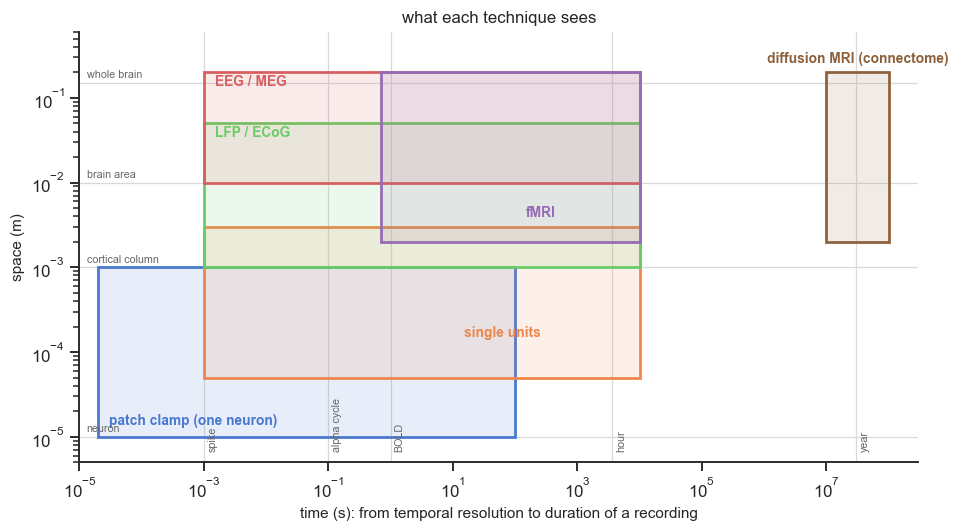

In [4]:
methods = {  # name: (space min, space max [m], time min, time max [s], label position)
    "patch clamp (one neuron)": (1e-5, 1e-3, 2e-5, 1e2, (3e-5, 1.4e-5)),
    "single units": (5e-5, 3e-3, 1e-3, 1e4, (1.5e1, 1.5e-4)),
    "LFP / ECoG": (1e-3, 5e-2, 1e-3, 1e4, (1.5e-3, 3.5e-2)),
    "EEG / MEG": (1e-2, 2e-1, 1e-3, 1e4, (1.5e-3, 1.4e-1)),
    "fMRI": (2e-3, 2e-1, 7e-1, 1e4, (1.5e2, 4e-3)),
    "diffusion MRI (connectome)": (2e-3, 2e-1, 1e7, 1e8, (1.1e6, 2.6e-1)),
}
fig, ax = plt.subplots(figsize=(9, 5))
for (name, (x0, x1, t0, t1, (lt, lx))), c in zip(methods.items(), plotting.COLORS):
    ax.add_patch(plt.Rectangle((t0, x0), t1 - t0, x1 - x0, facecolor=c, alpha=0.12, lw=0))
    ax.add_patch(plt.Rectangle((t0, x0), t1 - t0, x1 - x0, fill=False, edgecolor=c, lw=1.8))
    ax.text(lt, lx, name, color=c, fontsize=9, fontweight="bold")
ax.set(xscale="log", yscale="log", xlim=(1e-5, 3e8), ylim=(5e-6, 0.6),
       xlabel="time (s): from temporal resolution to duration of a recording", ylabel="space (m)",
       title="what each technique sees")
for y, lab in [(1e-5, "neuron"), (1e-3, "cortical column"), (1e-2, "brain area"), (1.5e-1, "whole brain")]:
    ax.axhline(y, c="0.85", lw=0.8, zorder=0); ax.text(1.3e-5, y * 1.15, lab, fontsize=7, color="0.4")
for x, lab in [(1e-3, "spike"), (1e-1, "alpha cycle"), (1, "BOLD"), (3600, "hour"), (3e7, "year")]:
    ax.axvline(x, c="0.85", lw=0.8, zorder=0); ax.text(x * 1.15, 7e-6, lab, fontsize=7, color="0.4", rotation=90)
plt.tight_layout()

## 2. One human neuron

A neuron from layer 3 of the frontal cortex of a 26-year-old patient, in tissue removed during surgery, kept alive in a
dish and recorded with a glass electrode (*patch clamp*). The experimenter injects a 1-second step of current and records the
membrane voltage. First, the cell itself (its reconstructed morphology):

Allen Cell Types Database (celltypes.brain-map.org), specimen 531523484 (H16.06.007.01.07.03): human frontal lobe, layer 3, spiny neuron, 26-year-old donor (tissue resected during tumour surgery). Long square current steps; V in mV, I in pA, t in s. Morphology: SWC columns id, type, x, y, z, radius, parent (um).


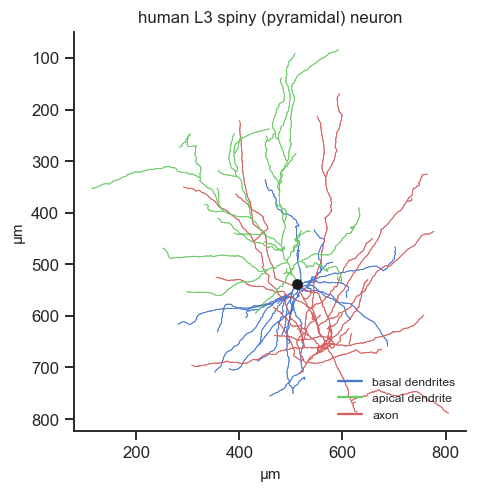

In [5]:
cell = np.load(f"{DATA}/human_neuron_allen_531523484.npz")
info(cell)
m = cell["morph"]                                   # id, type, x, y, z, radius, parent
idx = {int(i): k for k, i in enumerate(m[:, 0])}
fig, ax = plt.subplots(figsize=(4.5, 6))
colors = {1: "k", 2: "C3", 3: "C0", 4: "C2"}         # soma, axon, basal dendrite, apical dendrite
for row in m:
    p = int(row[6])
    if p in idx:
        q = m[idx[p]]
        ax.plot([q[2], row[2]], [q[3], row[3]], c=colors.get(int(row[1]), "0.5"), lw=0.6)
soma = m[m[:, 1] == 1]
ax.plot(soma[:, 2].mean(), soma[:, 3].mean(), "ko", ms=6)
for k, lab in [(3, "basal dendrites"), (4, "apical dendrite"), (2, "axon")]:
    ax.plot([], [], c=colors[k], label=lab)
ax.invert_yaxis()                                     # pia (brain surface) at the top
ax.set(aspect="equal", xlabel="µm", ylabel="µm", title="human L3 spiny (pyramidal) neuron"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()

smallest current that makes the cell fire: 310 pA


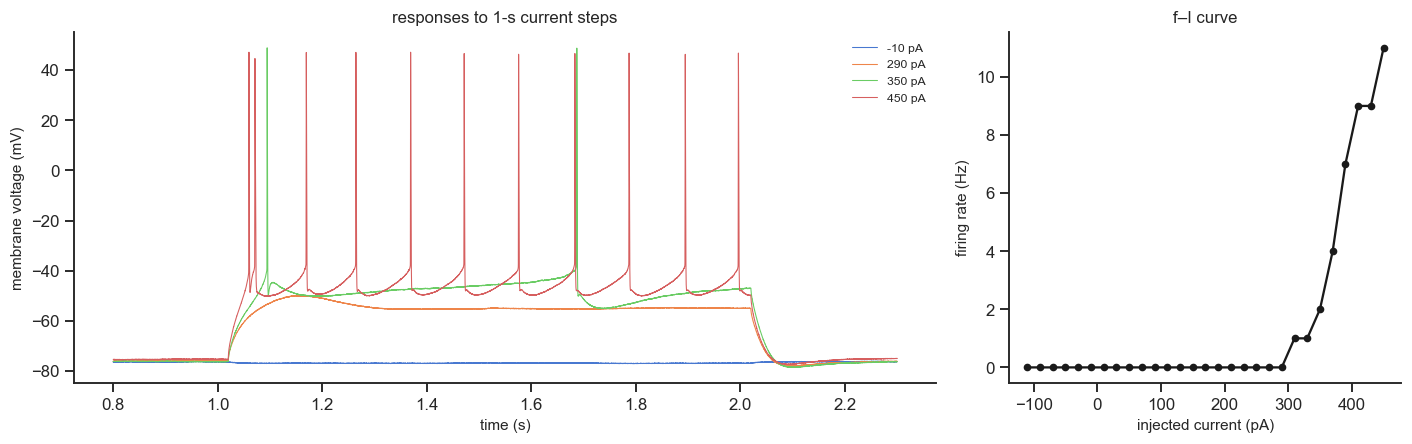

In [6]:
t, V, I, amps = cell["t"], cell["V"], cell["I"], cell["amps"]
dt = t[1] - t[0]
on = (t > 1.02) & (t < 2.02)                                 # the current step
n_spikes = np.array([np.sum((v[:-1] < 0) & (v[1:] >= 0) & on[1:]) for v in V])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[2.2, 1]))
for k, c in zip([5, 20, 23, 28], ["C0", "C1", "C2", "C3"]):
    ax[0].plot(t, V[k], c=c, lw=0.7, label=f"{amps[k]:.0f} pA")
ax[0].set(xlabel="time (s)", ylabel="membrane voltage (mV)", title="responses to 1-s current steps"); ax[0].legend(fontsize=8)
ax[1].plot(amps, n_spikes / 1.0, "o-", c="k", ms=4)
ax[1].set(xlabel="injected current (pA)", ylabel="firing rate (Hz)", title="f–I curve")
plt.tight_layout()
print(f"smallest current that makes the cell fire: {amps[np.argmax(n_spikes > 0)]:.0f} pA")

* Below a threshold current the voltage just shifts; above it the neuron fires **spikes**: all-or-none, ~100 mV,
  ~1 ms (look closely: they all have the same shape).
* More current → more spikes: the **f–I curve**. The spikes are not regular: the first intervals are short, then the
  neuron slows down (*adaptation*).
* NB01 builds the classic model of how spikes are generated (Hodgkin–Huxley); NB02 the simplest models that keep the
  essence (QIF, phase models).

### Explore: all the current steps

In [7]:
@interact(sweep=(0, len(amps) - 1, 1))
def explore_neuron(sweep):
    fig, ax = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
    ax[0].plot(t, V[sweep], "k", lw=0.7); ax[0].set(ylabel="voltage (mV)", ylim=(-100, 60), title=f"step of {amps[sweep]:.0f} pA: {n_spikes[sweep]} spikes")
    ax[1].plot(t, I[sweep], "C3"); ax[1].set(xlabel="time (s)", ylabel="current (pA)", ylim=(-150, 500))
    plt.tight_layout(); plt.show()

interactive(children=(IntSlider(value=14, description='sweep', max=28), Output()), _dom_classes=('widget-inter…

## 3. A handful of neurons in a living human brain

Patients with drug-resistant epilepsy are sometimes implanted with depth electrodes to locate the origin of their seizures.
Thin microwires at the tip pick up the spikes of individual neurons nearby (*single units*). Here: 16 neurons in the
amygdala, recorded while the patient looked at pictures (animals, fruit, cars, ...) and later had to say whether each
picture was new or already seen.

DANDI:000004 (Chandravadia et al. 2020, Sci Data 7:78; Faraut et al. 2018), subject P19HMH, human amygdala single units (microwires) during a declarative-memory task (images shown during 'learn' and 'recog' phases). Times in s. License CC-BY 4.0.


[]

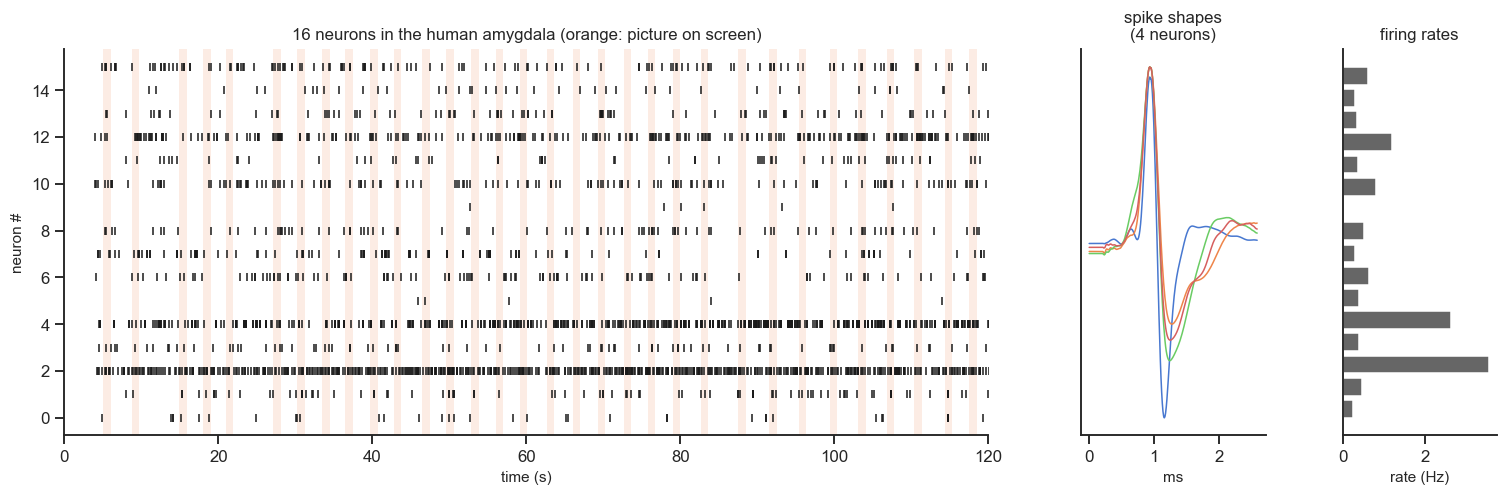

In [8]:
u = np.load(f"{DATA}/human_units_dandi000004.npz")
info(u)
spikes = [u["spike_times"][a:b] for a, b in zip(u["unit_start"], u["unit_stop"])]
rates = [len(s) / (u["spike_times"].max() - u["spike_times"].min()) for s in spikes]
fig = plt.figure(figsize=(14, 4.5))
ax0 = fig.add_axes([0.05, 0.13, 0.6, 0.78])
for k, s in enumerate(spikes):
    ax0.plot(s, np.full(len(s), k), "|", c="k", ms=5)
for x in u["stim_on"]:
    ax0.axvspan(x, x + 1.0, color="C1", alpha=0.15, lw=0)
ax0.set(xlim=(0, 120), xlabel="time (s)", ylabel="neuron #", title="16 neurons in the human amygdala (orange: picture on screen)")
ax1 = fig.add_axes([0.71, 0.13, 0.12, 0.78])
w = u["waveforms"]; tw = np.arange(w.shape[1]) / u["waveform_fs"] * 1e3
for k in [2, 4, 7, 14]:
    ax1.plot(tw, w[k] / np.abs(w[k]).max(), lw=1)
ax1.set(xlabel="ms", title="spike shapes\n(4 neurons)"); ax1.set_yticks([])
ax2 = fig.add_axes([0.88, 0.13, 0.1, 0.78])
ax2.barh(np.arange(16), rates, color="0.4"); ax2.set(xlabel="rate (Hz)", title="firing rates"); ax2.set_yticks([])

* Neurons fire **sparsely** (most below 1 Hz) and **irregularly**: no two neurons look alike.
* Each neuron has its own spike shape on the electrode: this is how spikes are assigned to neurons (*spike sorting*).

Do these neurons respond to the pictures? Align the spikes to picture onset and average over the 150 trials (*peri-stimulus
time histogram*, PSTH):

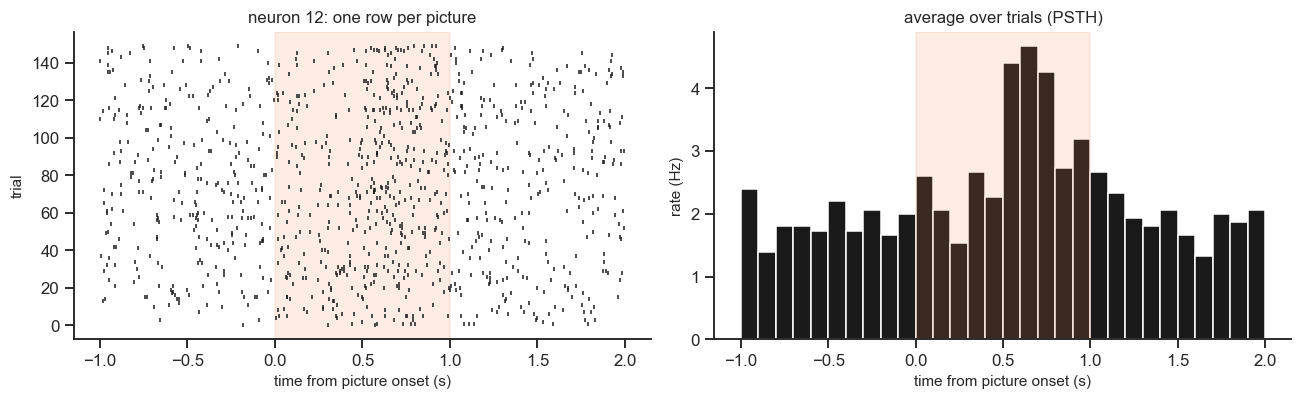

In [7]:
bins = np.arange(-1, 2.01, 0.1)
on_times = u["stim_on"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
psth = np.array([np.histogram(np.concatenate([s - x for x in on_times]), bins)[0] / len(on_times) / 0.1 for s in spikes])
z = (psth - psth[:, bins[:-1] < 0].mean(1, keepdims=True)) / (psth[:, bins[:-1] < 0].std(1, keepdims=True) + 1e-9)
best = np.argmax(z[:, (bins[:-1] > 0.1) & (bins[:-1] < 1.0)].max(1))
s = spikes[best]
for k, x in enumerate(on_times):
    rel = s[(s > x - 1) & (s < x + 2)] - x
    ax[0].plot(rel, np.full(len(rel), k), "|", c="k", ms=3)
ax[0].axvspan(0, 1, color="C1", alpha=0.15); ax[0].set(xlabel="time from picture onset (s)", ylabel="trial", title=f"neuron {best}: one row per picture")
ax[1].bar(bins[:-1] + 0.05, psth[best], width=0.1, color="k"); ax[1].axvspan(0, 1, color="C1", alpha=0.15)
ax[1].set(xlabel="time from picture onset (s)", ylabel="rate (Hz)", title="average over trials (PSTH)")
plt.tight_layout()

Single trials are noisy, the average reveals the response: a neuron's firing changes after the picture appears, with a
delay of a few hundred milliseconds. Brains work with populations of such noisy, sparse neurons; NB03–04 build networks of
them.

## 4. Millions of neurons: EEG

Electrodes on the scalp record voltage fluctuations produced by the synaptic currents of millions of aligned pyramidal
neurons firing together. Single spikes are invisible here: EEG sees **population activity**. One minute with eyes open,
one minute with eyes closed, same person:

PhysioNet EEG Motor Movement/Imagery Dataset (Schalk et al. 2004; Goldberger et al. 2000), subject S001, run 1 (eyes open) and run 2 (eyes closed) baselines, 1 min each, 160 Hz, microvolts. License ODC-By 1.0.


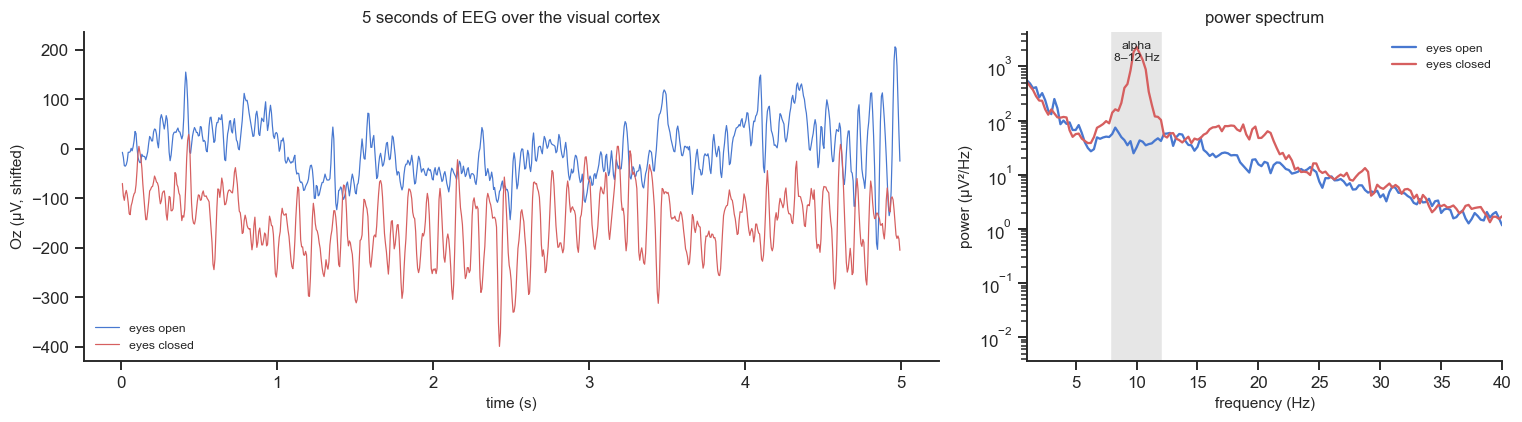

In [8]:
e = np.load(f"{DATA}/eeg_physionet_s001.npz")
info(e)
fs, ch = float(e["fs"]), list(e["channels"])
te = np.arange(e["eyes_open"].shape[1]) / fs
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw=dict(width_ratios=[1.8, 1]))
for k, (cond, c) in enumerate([("eyes_open", "C0"), ("eyes_closed", "C3")]):
    x = e[cond][ch.index("Oz")]
    sel = (te > 20) & (te < 25)
    ax[0].plot(te[sel] - 20, x[sel] - 150 * k, c=c, lw=0.8, label=cond.replace("_", " "))
    f, P = welch(x, fs=fs, nperseg=int(4 * fs))
    ax[1].semilogy(f, P, c=c, lw=1.5, label=cond.replace("_", " "))
ax[0].set(xlabel="time (s)", ylabel="Oz (µV, shifted)", title="5 seconds of EEG over the visual cortex"); ax[0].legend(fontsize=8)
ax[1].axvspan(8, 12, color="0.9"); ax[1].text(10, ax[1].get_ylim()[1] * 0.3, "alpha\n8–12 Hz", ha="center", fontsize=8)
ax[1].set(xlim=(1, 40), xlabel="frequency (Hz)", ylabel="power (µV²/Hz)", title="power spectrum"); ax[1].legend(fontsize=8)
plt.tight_layout()

Closing the eyes produces a strong **alpha rhythm** (~10 Hz) over the back of the head: millions of neurons oscillating
together. A rhythm in EEG is a **collective oscillation** of a population, the phenomenon we will model with spiking
networks (NB03–04) and their exact mean fields (NB05–06), and classify with bifurcation theory (NB07–08).

### Explore: channels and conditions
Is the alpha rhythm equally strong at the front (Fz), top (Cz) and back (O1, Oz, O2) of the head?

In [9]:
# @interact(channel=ch, condition=["eyes_open", "eyes_closed"])
def explore_eeg(channel, condition):
    x = e[condition][ch.index(channel)]
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.3), gridspec_kw=dict(width_ratios=[1.8, 1]))
    sel = (te > 20) & (te < 25)
    ax[0].plot(te[sel] - 20, x[sel], "k", lw=0.8); ax[0].set(xlabel="time (s)", ylabel="µV", title=f"{channel}, {condition.replace('_', ' ')}", ylim=(-150, 150))
    for cond, c in [("eyes_open", "C0"), ("eyes_closed", "C3")]:
        f, P = welch(e[cond][ch.index(channel)], fs=fs, nperseg=int(4 * fs)); ax[1].semilogy(f, P, c=c, label=cond.replace("_", " "))
    ax[1].set(xlim=(1, 40), ylim=(1e-1, 1e4), xlabel="frequency (Hz)", title="spectrum"); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

interactive(children=(Dropdown(description='channel', options=(np.str_('O1'), np.str_('Oz'), np.str_('O2'), np…

## 5. The whole brain: resting-state fMRI

fMRI measures the Blood-oxygenation-level–dependent **(BOLD)** signal: changes in blood oxygenation that follow neural activity with a delay of a few seconds. It is slow (one image every 0.72 s here, and the signal itself varies over ~10–100 s) and indirect, but it sees the
whole brain at once, at a resolution of ~2 mm.

The figures below come from one subject of the **Human Connectome Project** (HCP, subject 100206), lying still in the
scanner with nothing to do (*resting state*), with the cortex divided into 400 regions (Schaefer atlas). HCP data are
free but require accepting the HCP data-use terms: register at
[db.humanconnectome.org](https://db.humanconnectome.org) to access them yourself. Here we only show figures we made.

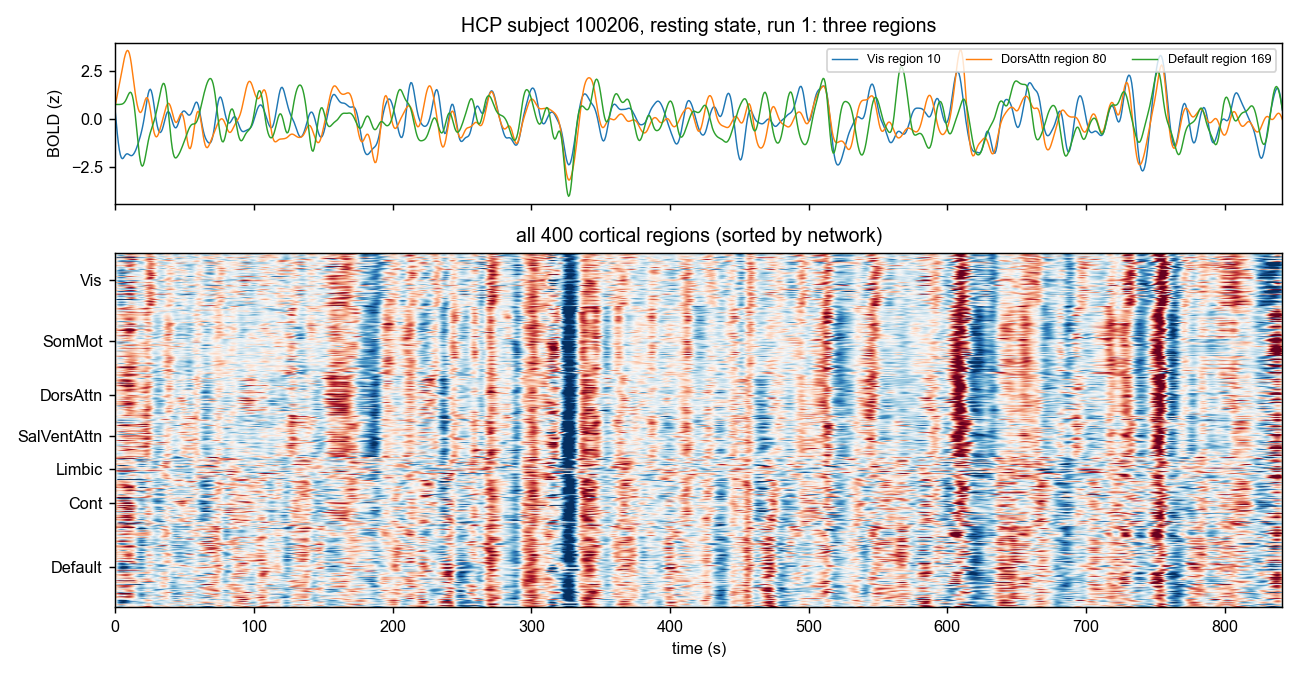

In [10]:
display(Image("../figures/data_tour/hcp_bold.png", width=900))

* Activity fluctuates slowly and spontaneously, without any task.
* Many regions go up and down **together** (vertical stripes in the bottom panel), and regions of the same *network*
  (visual, somatomotor, default mode, ...) tend to move together.

The correlation between every pair of regions is the **functional connectivity (FC)**:

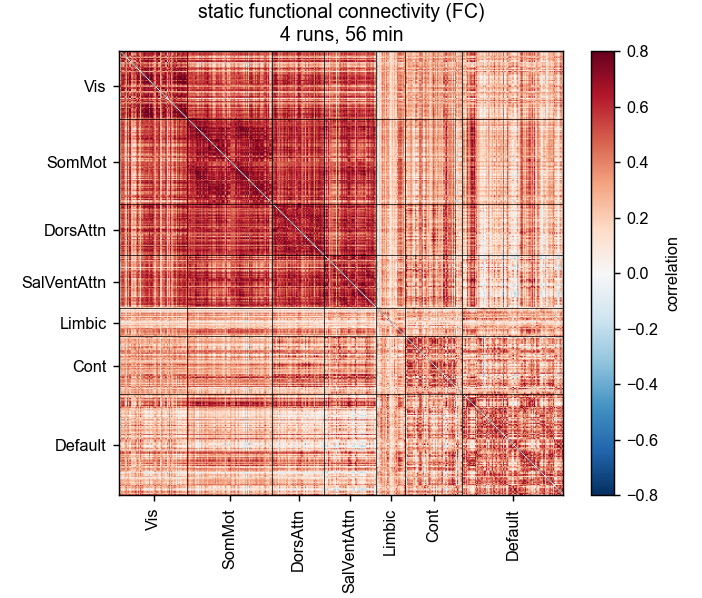

In [11]:
display(Image("../figures/data_tour/hcp_fc.png", width=480))

FC has structure: blocks of strongly correlated regions (the networks). But FC is not fixed: computed in 60-second windows it
changes over time. Comparing the FC of every window with every other gives the **dynamic FC** (FCD) matrix: bright squares
are periods during which the brain stays in a similar configuration, then it switches.

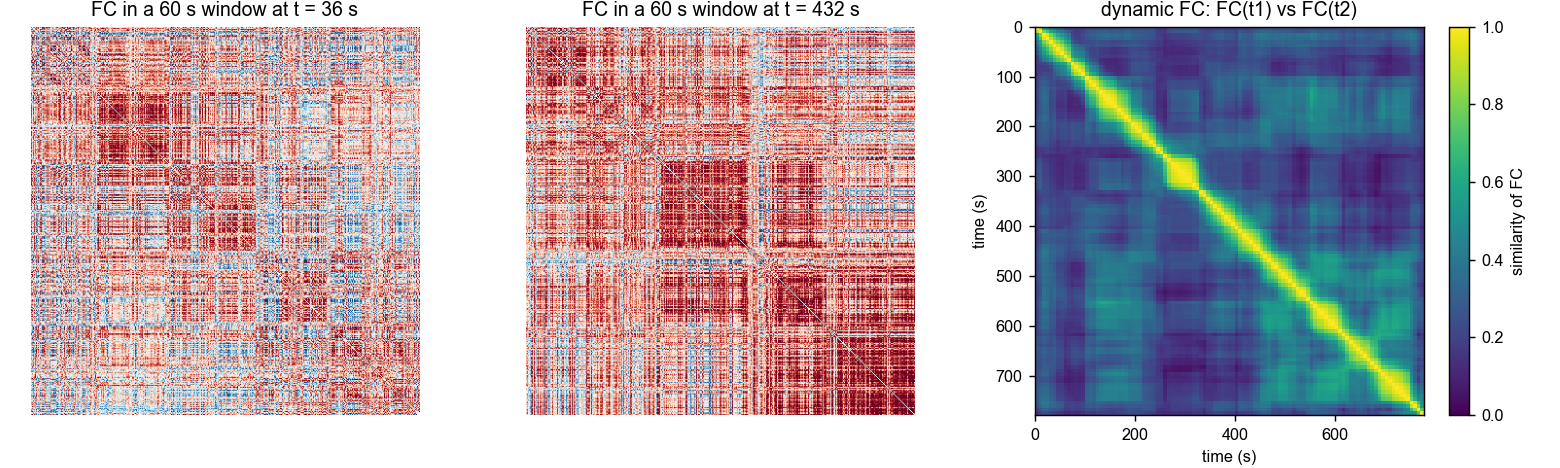

In [12]:
display(Image("../figures/data_tour/hcp_dfc.png", width=1000))

Whole-brain models (Chapter 5) aim to reproduce exactly these features: slow spontaneous fluctuations, the FC matrix, and
its changes over time (FCD), starting from the wiring of the brain.

## 6. The wiring: the structural connectome

Diffusion MRI tracks the bundles of white-matter fibres that connect brain regions. Averaging over many HCP subjects gives a
**structural connectivity (SC)** matrix (ENIGMA toolbox, 100 cortical regions). It comes with the group-average FC of the same
regions, so we can ask: does structure predict function?

22% of region pairs are directly connected


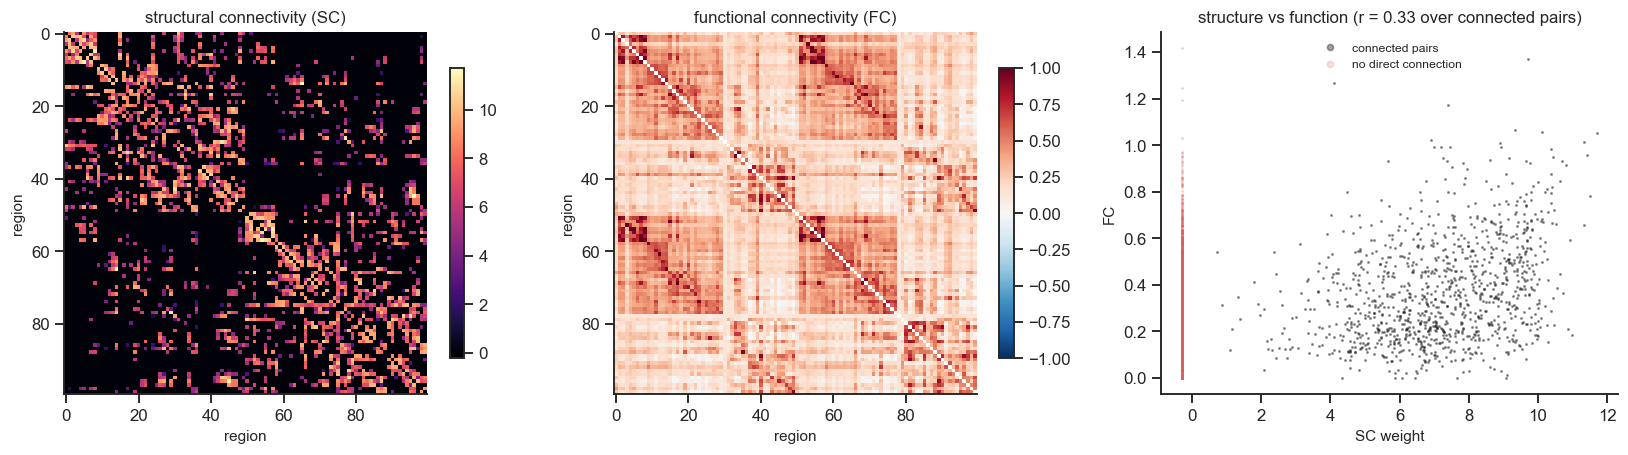

In [13]:
sc, fc, labels = load_hcp("schaefer100", normalize=False)
np.fill_diagonal(fc, np.nan)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
im = ax[0].imshow(sc, cmap="magma"); plt.colorbar(im, ax=ax[0], shrink=0.8); ax[0].set_title("structural connectivity (SC)")
im = ax[1].imshow(fc, cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar(im, ax=ax[1], shrink=0.8); ax[1].set_title("functional connectivity (FC)")
for a_ in ax[:2]: a_.set(xlabel="region", ylabel="region")
iu = np.triu_indices_from(sc, 1)
conn = sc[iu] > 0
ax[2].plot(sc[iu][conn], fc[iu][conn], ".", ms=2, alpha=0.4, c="k", label="connected pairs")
ax[2].plot(np.zeros((~conn).sum()) - 0.3, fc[iu][~conn], ".", ms=2, alpha=0.2, c="C3", label="no direct connection")
r = np.corrcoef(sc[iu][conn], fc[iu][conn])[0, 1]
ax[2].set(xlabel="SC weight", ylabel="FC", title=f"structure vs function (r = {r:.2f} over connected pairs)"); ax[2].legend(fontsize=8, markerscale=4)
plt.tight_layout()
print(f"{conn.mean():.0%} of region pairs are directly connected")

Structure and function are related (strongly connected regions tend to be correlated) but far from identical: some regions are
correlated **without** a direct connection, and the same SC supports many different FC patterns over time (the FCD above). The
missing link is **dynamics**: what each region does, and how signals travel and interact on the network. This is what
whole-brain models add (Chapter 5).

## 7. Take-home: what our models must explain

| observation | scale | model |
|---|---|---|
| all-or-none spikes, a threshold, f–I curve, adaptation | one neuron | Hodgkin–Huxley, QIF, phase models (NB01–02) |
| sparse, irregular firing; noisy single trials | neurons | spiking networks (NB03–04) |
| rhythms (alpha), collective oscillations | populations | mean fields, bifurcations (NB05–08) |
| slow fluctuations, FC, dynamic FC, structure ≠ function | whole brain | connectome-based models near a bifurcation (Ch. 5) |

Each technique is a different window, and each model a different map. In this course we move from the left column to the right,
keeping track of what each simplification keeps and what it throws away.

### Homework
*To do at home, after the class. In class we use the **Explore** sliders; these exercises take the same
questions further and usually need a few lines of your own code.*
1. **f–I curve.** Is the neuron's f–I curve continuous (firing starts at low rates, type I) or does it jump to a finite rate
   (type II)? Keep this question for NB02.
2. **Regularity.** For each amygdala neuron compute the coefficient of variation of its inter-spike intervals (std/mean).
   A clock has CV = 0, a Poisson process CV = 1. What do you find? (We will meet CV > 1 again in NB08.)
3. **Alpha map.** For each EEG channel, compute the ratio of alpha power (8–12 Hz) between eyes closed and eyes open. Where is it
   largest?
4. **SC → FC.** Correlate SC and FC using all pairs (including unconnected ones) and using log(SC). Which is better? Can you
   think of a quantity that would predict FC for unconnected pairs (hint: paths through intermediate regions)?

### Data sources and references
* Allen Cell Types Database, celltypes.brain-map.org; Gouwens NW et al. (2019) *Nat Neurosci* 22:1182; Berg J et al. (2021) Human neocortical expansion involves glutamatergic neuron diversification. *Nature* 598:151.
* Chandravadia N et al. (2020). A NWB-based dataset and processing pipeline of human single-neuron activity during a declarative memory task. *Sci Data* 7:78 (DANDI:000004).
* Schalk G et al. (2004) BCI2000. *IEEE Trans Biomed Eng* 51:1034; Goldberger AL et al. (2000) PhysioBank, PhysioToolkit, PhysioNet. *Circulation* 101:e215.
* Van Essen DC et al. (2013). The WU-Minn Human Connectome Project: an overview. *NeuroImage* 80:62. Schaefer A et al. (2018) *Cereb Cortex* 28:3095.
* Larivière S et al. (2021). The ENIGMA Toolbox. *Nat Methods* 18:698.
* Buzsáki G, Anastassiou CA, Koch C (2012). The origin of extracellular fields and currents — EEG, ECoG, LFP and spikes. *Nat Rev Neurosci* 13:407.
* Logothetis NK (2008). What we can do and what we cannot do with fMRI. *Nature* 453:869.
* Honey CJ et al. (2009). Predicting human resting-state functional connectivity from structural connectivity. *PNAS* 106:2035.